
# Predictive Maintenance & Failure Explanation System

## Project Overview

This project uses machine learning to estimate the probability of machine failure based on operating measurements.

The system uses the AI4I 2020 Predictive Maintenance Dataset and compares Logistic Regression with Random Forest classification.

### Objectives
- Explore machine operating data and failure patterns.
- Train and evaluate machine-failure classification models.
- Address class imbalance and compare precision, recall, and F1-score.
- Select a prediction threshold using validation data.
- Display predictions and potential risk indicators in a Streamlit application.

**Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, Joblib and Streamlit.


In [1]:
# Step 1: Import essential libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Libraries imported successfully!")

Libraries imported successfully!



## 1. Dataset Loading and Understanding

Load the AI4I 2020 dataset and inspect its dimensions, column names, data types, sample records, and data quality.


In [2]:
# Step 2: Load the dataset

import pandas as pd

df = pd.read_csv("ai4i2020.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (10000, 14)


In [3]:
# Step 3: Understand the dataset

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0



Column names:
['UDI', 'Product ID', 'Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF     


## 2. Exploratory Data Analysis (EDA)

Examine the distribution of machine failures, explore failure-mode indicators, and visualize operating measurements to identify patterns associated with machine failure.


Machine Failure Counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Machine Failure Percentage:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


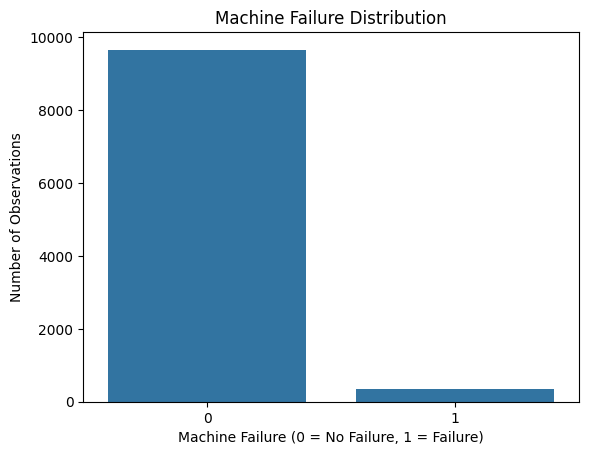

In [4]:
# Step 4: Analyze machine failure distribution

print("Machine Failure Counts:")
print(df["Machine failure"].value_counts())

print("\nMachine Failure Percentage:")
print(
    (df["Machine failure"].value_counts(normalize=True) * 100).round(2)
)

# Visualize the distribution
sns.countplot(data=df, x="Machine failure")
plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure (0 = No Failure, 1 = Failure)")
plt.ylabel("Number of Observations")
plt.show()

In [5]:
# Step 5: Analyze the five failure modes

failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

print("Failure-mode counts:")
print(df[failure_columns].sum())

print("\nMachine failure target counts:")
print(df["Machine failure"].value_counts())

Failure-mode counts:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19
dtype: int64

Machine failure target counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64


In [6]:
# Count rows where more than one failure mode is recorded

failure_mode_count = df[failure_columns].sum(axis=1)

print("Rows with multiple failure modes:")
print((failure_mode_count > 1).sum())

print("\nRows with machine failure but no listed failure mode:")
print(((df["Machine failure"] == 1) & (failure_mode_count == 0)).sum())

print("\nRows with a listed failure mode but no machine failure:")
print(((df["Machine failure"] == 0) & (failure_mode_count > 0)).sum())

Rows with multiple failure modes:
24

Rows with machine failure but no listed failure mode:
9

Rows with a listed failure mode but no machine failure:
18


In [7]:
# Check the relationship between the target and failure modes

failure_mode_count = df[failure_columns].sum(axis=1)

print("Total machine failures:",
      (df["Machine failure"] == 1).sum())

print("Rows with at least one failure mode:",
      (failure_mode_count > 0).sum())

print("Total positive failure-mode indicators:",
      df[failure_columns].sum().sum())

print("\nFirst 10 inconsistent rows:")
display(
    df.loc[
        (df["Machine failure"] != (failure_mode_count > 0).astype(int)),
        ["UDI", "Machine failure"] + failure_columns
    ].head(10)
)

Total machine failures: 339
Rows with at least one failure mode: 348
Total positive failure-mode indicators: 373

First 10 inconsistent rows:


,UDI,Machine failure,TWF,HDF,PWF,OSF,RNF
1221,1222,0,0,0,0,0,1
1302,1303,0,0,0,0,0,1
1437,1438,1,0,0,0,0,0
1748,1749,0,0,0,0,0,1
2072,2073,0,0,0,0,0,1
2559,2560,0,0,0,0,0,1
2749,2750,1,0,0,0,0,0
3065,3066,0,0,0,0,0,1
3452,3453,0,0,0,0,0,1
4044,4045,1,0,0,0,0,0


In [8]:
# Check whether the four main failure modes match the target

main_failure_modes = ["TWF", "HDF", "PWF", "OSF"]

print("Rows with any of the four main failure modes:")
print((df[main_failure_modes].sum(axis=1) > 0).sum())

print("\nMachine failures with none of the four main modes:")
print(
    (
        (df["Machine failure"] == 1) &
        (df[main_failure_modes].sum(axis=1) == 0)
    ).sum()
)

Rows with any of the four main failure modes:
330

Machine failures with none of the four main modes:
9


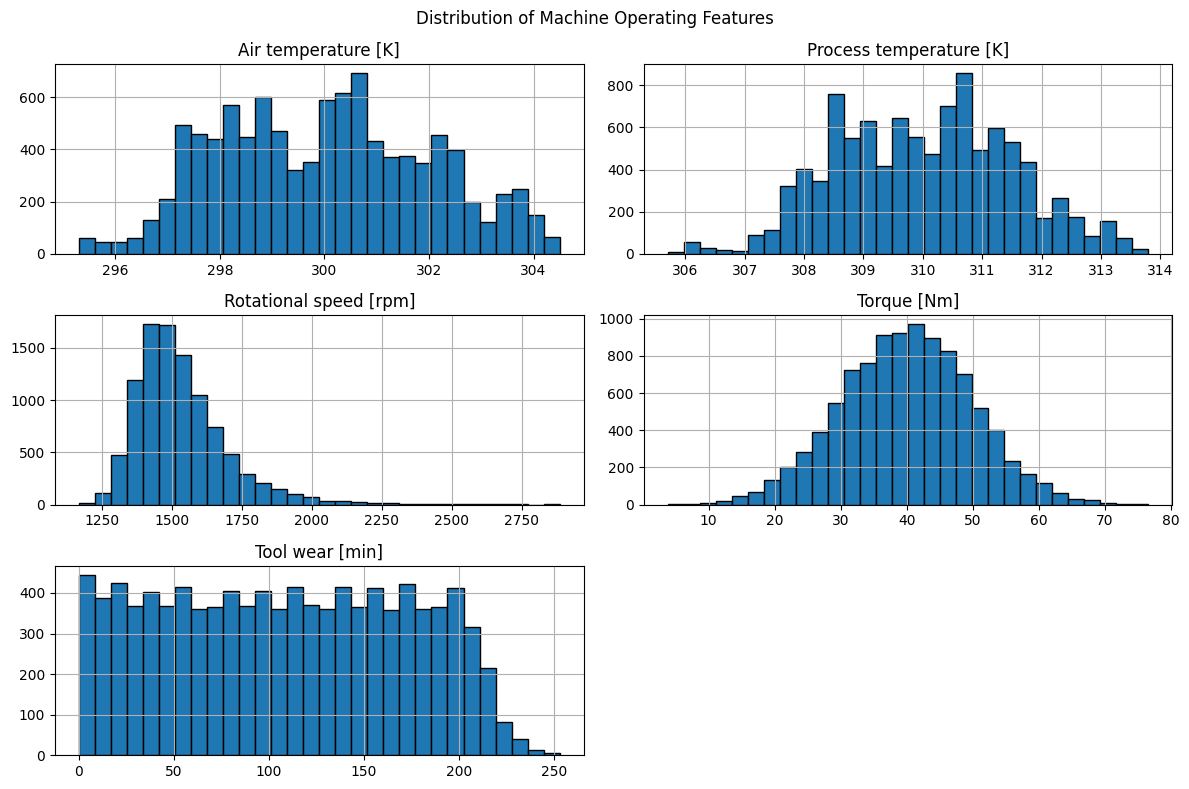

In [9]:
# Step 6: Explore numerical features

numerical_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df[numerical_features].hist(
    figsize=(12, 8),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Machine Operating Features")
plt.tight_layout()
plt.show()

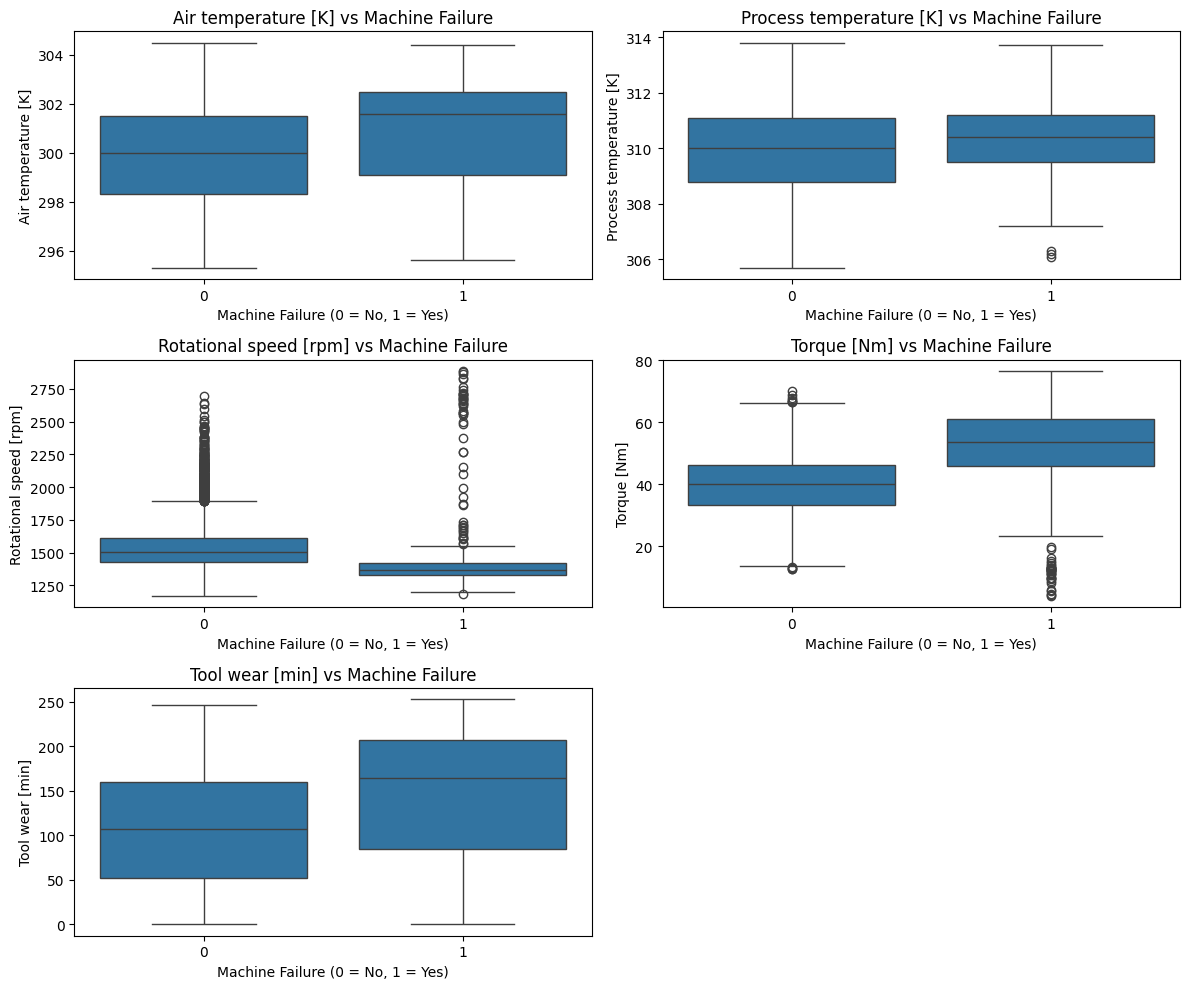

In [10]:

# Step 7: Compare features by machine failure status using subplots

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

axes = axes.flatten()

for i, feature in enumerate(numerical_features):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(f"{feature} vs Machine Failure")
    axes[i].set_xlabel("Machine Failure (0 = No, 1 = Yes)")

# Remove the unused sixth subplot
fig.delaxes(axes[5])

plt.tight_layout()
plt.show()



## 3. Feature Selection and Preprocessing

Select relevant machine operating measurements as input features and use Machine failure as the target variable.

Exclude identifiers and failure-mode outcome columns to reduce leakage risk. Encode the categorical machine Type column using one-hot encoding.


In [11]:

# Step 8: Prepare features (X) and target (y)

features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features].copy()
y = df["Machine failure"].copy()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())


Feature shape: (10000, 6)
Target shape: (10000,)


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


0    0
1    0
2    0
3    0
4    0
Name: Machine failure, dtype: int64

In [12]:

# Step 9: Encode the categorical feature

X = pd.get_dummies(
    X,
    columns=["Type"],
    dtype=int
)

print("Features after encoding:")
display(X.head())

print("\nNew feature shape:", X.shape)


Features after encoding:


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Type_H,Type_L,Type_M
0,298.1,308.6,1551,42.8,0,0,0,1
1,298.2,308.7,1408,46.3,3,0,1,0
2,298.1,308.5,1498,49.4,5,0,1,0
3,298.2,308.6,1433,39.5,7,0,1,0
4,298.2,308.7,1408,40.0,9,0,1,0



New feature shape: (10000, 8)



## 4. Data Splitting

Split the dataset into training, validation, and test subsets.

Use stratification to preserve the rare machine-failure class proportions. Use training data to fit models, validation data to select the prediction threshold, and test data for final evaluation.


In [13]:

# Step 10: Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (8000, 8)
Testing features: (2000, 8)

Training target distribution:
Machine failure
0    7729
1     271
Name: count, dtype: int64

Testing target distribution:
Machine failure
0    1932
1      68
Name: count, dtype: int64



## 5. Model 1: Logistic Regression

Train a Logistic Regression classifier with feature scaling and class weighting.

Evaluate the model using precision, recall, F1-score, accuracy, and a confusion matrix. Because failures are rare, pay particular attention to failure recall and false alarms.


In [14]:

# Step 11: Train a Logistic Regression model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create the model
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
)

# Train the model
lr_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [15]:

# Step 12: Evaluate Logistic Regression

y_pred = lr_model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.83      0.90      1932
           1       0.14      0.82      0.24        68

    accuracy                           0.82      2000
   macro avg       0.57      0.82      0.57      2000
weighted avg       0.96      0.82      0.88      2000

Confusion Matrix:
[[1594  338]
 [  12   56]]



## 6. Model 2: Random Forest

Train a Random Forest classifier using class weighting to address the imbalanced target.

Evaluate its ability to identify actual failures and compare its performance with Logistic Regression.


In [16]:

# Step 13: Train a Random Forest model

from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")


Random Forest model trained successfully!


In [17]:

# Step 14: Evaluate the Random Forest model

y_pred_rf = rf_model.predict(X_test)

print("Random Forest Classification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("Random Forest Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))


Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.91      0.43      0.58        68

    accuracy                           0.98      2000
   macro avg       0.94      0.71      0.78      2000
weighted avg       0.98      0.98      0.98      2000

Random Forest Confusion Matrix:
[[1929    3]
 [  39   29]]


Feature Importance:
Rotational speed [rpm]     0.309927
Torque [Nm]                0.292754
Tool wear [min]            0.200449
Air temperature [K]        0.103700
Process temperature [K]    0.073200
Type_L                     0.009904
Type_M                     0.006288
Type_H                     0.003777
dtype: float64


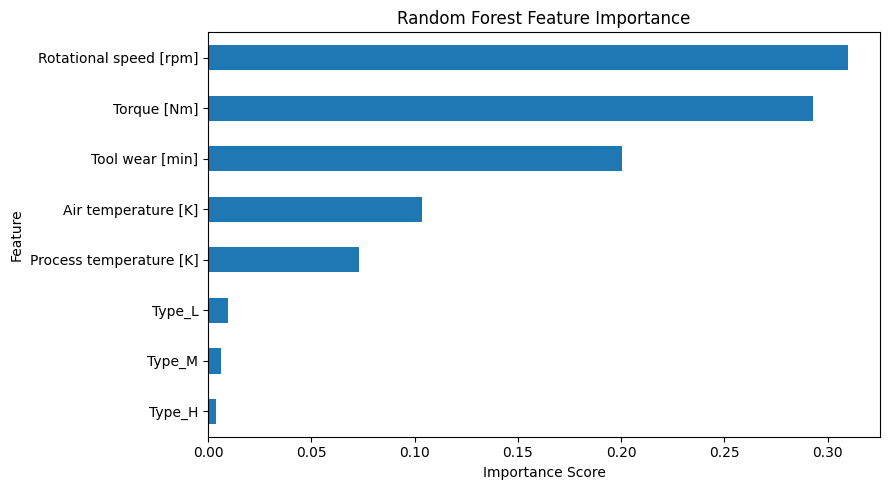

In [18]:

# Step 16: Visualize Random Forest feature importance

importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Feature Importance:")
print(importance)

plt.figure(figsize=(9, 5))
importance.sort_values().plot(kind="barh")

plt.title("Random Forest Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()



## 7. Model Comparison

Compare Logistic Regression and Random Forest using accuracy, failure precision, failure recall, and failure F1-score.

Do not select the best model using accuracy alone. Consider the trade-off between missed failures and false alarms.


In [19]:
# Step 17: Compare Logistic Regression and Random Forest

models_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, lr_model.predict(X_test)),
        accuracy_score(y_test, rf_model.predict(X_test))
    ],
    "Failure Precision": [
        precision_score(y_test, lr_model.predict(X_test), zero_division=0),
        precision_score(y_test, rf_model.predict(X_test), zero_division=0)
    ],
    "Failure Recall": [
        recall_score(y_test, lr_model.predict(X_test), zero_division=0),
        recall_score(y_test, rf_model.predict(X_test), zero_division=0)
    ],
    "Failure F1-score": [
        f1_score(y_test, lr_model.predict(X_test), zero_division=0),
        f1_score(y_test, rf_model.predict(X_test), zero_division=0)
    ]
})

print(models_comparison.round(3))

                 Model  Accuracy  Failure Precision  Failure Recall  \
0  Logistic Regression     0.825              0.142           0.824   
1        Random Forest     0.979              0.906           0.426   

   Failure F1-score  
0             0.242  
1             0.580  


In [20]:
# Step 19A: Create a validation set from the training data

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training set:", X_train_new.shape)
print("Validation set:", X_val.shape)
print("\nValidation target distribution:")
print(y_val.value_counts())

Training set: (6400, 8)
Validation set: (1600, 8)

Validation target distribution:
Machine failure
0    1546
1      54
Name: count, dtype: int64


In [21]:
# Step 19B: Train Random Forest on the new training subset

rf_tuned = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_tuned.fit(X_train_new, y_train_new)

print("New Random Forest model trained successfully!")

New Random Forest model trained successfully!



## 8. Prediction Threshold Selection

The default classification threshold may not be suitable when machine failures are rare.

Compare multiple thresholds using validation data to understand how the trade-off between precision and recall changes. Select a threshold based on the project's intended balance between missed failures and false alarms.


In [22]:
# Step 19C: Evaluate thresholds on the validation set

y_val_probability = rf_tuned.predict_proba(X_val)[:, 1]

for threshold in [0.5, 0.4, 0.3, 0.2]:
    y_val_pred = (y_val_probability >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Failure Precision:",
          round(precision_score(y_val, y_val_pred, zero_division=0), 3))
    print("Failure Recall:",
          round(recall_score(y_val, y_val_pred, zero_division=0), 3))
    print("Failure F1-score:",
          round(f1_score(y_val, y_val_pred, zero_division=0), 3))
    print("Confusion Matrix:")
    print(confusion_matrix(y_val, y_val_pred))


Threshold: 0.5
Failure Precision: 0.885
Failure Recall: 0.426
Failure F1-score: 0.575
Confusion Matrix:
[[1543    3]
 [  31   23]]

Threshold: 0.4
Failure Precision: 0.853
Failure Recall: 0.537
Failure F1-score: 0.659
Confusion Matrix:
[[1541    5]
 [  25   29]]

Threshold: 0.3
Failure Precision: 0.686
Failure Recall: 0.648
Failure F1-score: 0.667
Confusion Matrix:
[[1530   16]
 [  19   35]]

Threshold: 0.2
Failure Precision: 0.548
Failure Recall: 0.741
Failure F1-score: 0.63
Confusion Matrix:
[[1513   33]
 [  14   40]]



## 9. Final Model Evaluation

Evaluate the selected model and threshold on the held-out test set.

Report accuracy, failure precision, failure recall, failure F1-score, and the confusion matrix. These results provide a final assessment on data that was not used to select the threshold.


In [23]:
# Step 21: Final test evaluation using threshold 0.3

selected_threshold = 0.3

# Get failure probabilities for the test data
y_test_probability = rf_tuned.predict_proba(X_test)[:, 1]

# Convert probabilities into predictions using threshold 0.3
y_test_pred_tuned = (
    y_test_probability >= selected_threshold
).astype(int)

# Evaluate the model
print("Selected Threshold:", selected_threshold)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_tuned,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_tuned))

print("\nFailure Precision:",
      round(precision_score(y_test, y_test_pred_tuned, zero_division=0), 3))

print("Failure Recall:",
      round(recall_score(y_test, y_test_pred_tuned, zero_division=0), 3))

print("Failure F1-score:",
      round(f1_score(y_test, y_test_pred_tuned, zero_division=0), 3))

Selected Threshold: 0.3

Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      1932
           1       0.67      0.65      0.66        68

    accuracy                           0.98      2000
   macro avg       0.83      0.82      0.82      2000
weighted avg       0.98      0.98      0.98      2000

Confusion Matrix:
[[1910   22]
 [  24   44]]

Failure Precision: 0.667
Failure Recall: 0.647
Failure F1-score: 0.657


In [24]:
# Step 23: Create a basic failure explanation function

def explain_machine_readings(row):

    explanations = []

    if row["Rotational speed [rpm]"] < 1500:
        explanations.append(
            "Low rotational speed: inspect operating conditions."
        )

    if row["Torque [Nm]"] > 50:
        explanations.append(
            "High torque: check whether the machine is under excessive load."
        )

    if row["Tool wear [min]"] > 200:
        explanations.append(
            "High tool wear: consider checking tool condition."
        )

    if row["Air temperature [K]"] > 302:
        explanations.append(
            "Elevated air temperature: check the operating environment."
        )

    if row["Process temperature [K]"] > 312:
        explanations.append(
            "Elevated process temperature: inspect temperature conditions."
        )

    if not explanations:
        explanations.append(
            "No predefined warning conditions were triggered. "
            "This does not guarantee that the machine is safe."
        )

    return explanations

In [25]:
# Step 24: Test the explanation function on one test example

sample_machine = X_test.iloc[0].copy()

print("Machine readings:")
print(sample_machine)

print("\nPotential risk indicators:")
for explanation in explain_machine_readings(sample_machine):
    print("-", explanation)

Machine readings:
Air temperature [K]         300.5
Process temperature [K]     309.8
Rotational speed [rpm]     1345.0
Torque [Nm]                  62.7
Tool wear [min]             153.0
Type_H                        0.0
Type_L                        1.0
Type_M                        0.0
Name: 2997, dtype: float64

Potential risk indicators:
- Low rotational speed: inspect operating conditions.
- High torque: check whether the machine is under excessive load.



## 11. Example Prediction and Risk Indicators

Use a sample set of machine measurements to demonstrate failure-probability estimation and the model's alert decision.

Display potential risk indicators using predefined rules. These indicators are separate from the model's prediction and should not be interpreted as causal explanations.


In [26]:
# Step 25: Predict failure risk and explain the result

sample_machine = X_test.iloc[0].copy()

# Calculate the probability of machine failure
failure_probability = rf_tuned.predict_proba(
    sample_machine.to_frame().T
)[0, 1]

# Apply the selected threshold
if failure_probability >= 0.3:
    prediction = "Potential Machine Failure"
else:
    prediction = "No Failure Alert"

# Generate explanations
risk_indicators = explain_machine_readings(sample_machine)

# Display results
print("===== PREDICTIVE MAINTENANCE REPORT =====")

print(f"\nEstimated Failure Probability: {failure_probability:.2%}")

print(f"Prediction: {prediction}")

print("\nPotential Risk Indicators:")

for indicator in risk_indicators:
    print("-", indicator)

===== PREDICTIVE MAINTENANCE REPORT =====

Estimated Failure Probability: 12.50%
Prediction: No Failure Alert

Potential Risk Indicators:
- Low rotational speed: inspect operating conditions.
- High torque: check whether the machine is under excessive load.


In [27]:

# Step 27: Assign a risk category

if failure_probability < 0.10:
    risk_category = "Low Estimated Risk"
elif failure_probability < 0.30:
    risk_category = "Moderate Estimated Risk"
else:
    risk_category = "High Estimated Risk"

print("Estimated Failure Probability:",
      f"{failure_probability:.2%}")

print("Risk Category:", risk_category)

print("Model Prediction:", prediction)


Estimated Failure Probability: 12.50%
Risk Category: Moderate Estimated Risk
Model Prediction: No Failure Alert


In [28]:
# Step 28: Compare risk indicators with actual machine failures

df["Low_Rotational_Speed"] = (
    df["Rotational speed [rpm]"] < 1500
)

df["High_Torque"] = (
    df["Torque [Nm]"] > 50
)

df["High_Tool_Wear"] = (
    df["Tool wear [min]"] > 200
)

print("Low rotational speed:")
print(pd.crosstab(
    df["Low_Rotational_Speed"],
    df["Machine failure"],
    normalize="index"
).round(3))

print("\nHigh torque:")
print(pd.crosstab(
    df["High_Torque"],
    df["Machine failure"],
    normalize="index"
).round(3))

print("\nHigh tool wear:")
print(pd.crosstab(
    df["High_Tool_Wear"],
    df["Machine failure"],
    normalize="index"
).round(3))

Low rotational speed:
Machine failure           0      1
Low_Rotational_Speed              
False                 0.988  0.012
True                  0.943  0.057

High torque:
Machine failure      0      1
High_Torque                  
False            0.985  0.015
True             0.863  0.137

High tool wear:
Machine failure      0      1
High_Tool_Wear               
False            0.976  0.024
True             0.845  0.155


In [29]:
# Step 30: Update the explanation function

def explain_machine_readings(row):

    explanations = []

    if row["Rotational speed [rpm]"] < 1500:
        explanations.append(
            "Low rotational speed: observed failure rate was "
            "5.7% for this group in the dataset."
        )

    if row["Torque [Nm]"] > 50:
        explanations.append(
            "High torque: observed failure rate was "
            "13.7% for this group in the dataset."
        )

    if row["Tool wear [min]"] > 200:
        explanations.append(
            "High tool wear: observed failure rate was "
            "15.5% for this group in the dataset."
        )

    if not explanations:
        explanations.append(
            "No predefined risk indicators were triggered. "
            "This does not guarantee that the machine is safe."
        )

    return explanations

In [30]:
# Step 31: Test the updated explanation

sample_machine = X_test.iloc[0].copy()

risk_indicators = explain_machine_readings(sample_machine)

print("Potential Risk Indicators:")

for indicator in risk_indicators:
    print("-", indicator)

Potential Risk Indicators:
- Low rotational speed: observed failure rate was 5.7% for this group in the dataset.
- High torque: observed failure rate was 13.7% for this group in the dataset.


In [31]:
# Step 32: Create a reusable prediction function

def predict_machine_failure(machine_readings):

    # Convert the input dictionary into a DataFrame
    input_df = pd.DataFrame([machine_readings])

    # Encode the machine type
    input_df = pd.get_dummies(
        input_df,
        columns=["Type"],
        dtype=int
    )

    # Ensure the input has the same columns as the training data
    input_df = input_df.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    # Predict failure probability
    probability = rf_tuned.predict_proba(input_df)[0, 1]

    # Apply the selected threshold
    if probability >= 0.3:
        prediction = "Potential Machine Failure"
    else:
        prediction = "No Failure Alert"

    # Assign a risk category
    if probability < 0.10:
        risk = "Low Estimated Risk"
    elif probability < 0.30:
        risk = "Moderate Estimated Risk"
    else:
        risk = "High Estimated Risk"

    # Generate risk indicators
    explanations = explain_machine_readings(input_df.iloc[0])

    return {
        "failure_probability": round(probability, 4),
        "prediction": prediction,
        "risk_category": risk,
        "risk_indicators": explanations
    }

In [32]:
# Step 33: Test the complete prediction system

sample_input = {
    "Type": "L",
    "Air temperature [K]": 300.5,
    "Process temperature [K]": 309.8,
    "Rotational speed [rpm]": 1345,
    "Torque [Nm]": 62.7,
    "Tool wear [min]": 153
}

result = predict_machine_failure(sample_input)

print("===== PREDICTIVE MAINTENANCE REPORT =====")
print(f"Failure Probability: {result['failure_probability']:.2%}")
print("Prediction:", result["prediction"])
print("Risk Category:", result["risk_category"])

print("\nPotential Risk Indicators:")
for item in result["risk_indicators"]:
    print("-", item)

===== PREDICTIVE MAINTENANCE REPORT =====
Failure Probability: 12.50%
Prediction: No Failure Alert
Risk Category: Moderate Estimated Risk

Potential Risk Indicators:
- Low rotational speed: observed failure rate was 5.7% for this group in the dataset.
- High torque: observed failure rate was 13.7% for this group in the dataset.



## 12. Saving Model Artifacts

Save the trained Random Forest model and the ordered feature names so that the Streamlit application can load the model and make predictions using the same input structure as during training.


In [33]:
# Step 35: Save the trained model and feature information

import joblib

joblib.dump(rf_tuned, "predictive_maintenance_model.pkl")

joblib.dump(X_train.columns.tolist(), "model_features.pkl")

print("Model and feature information saved successfully!")

Model and feature information saved successfully!


In [34]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load the saved model and feature names
model = joblib.load("predictive_maintenance_model.pkl")
model_features = joblib.load("model_features.pkl")

# Page configuration
st.set_page_config(
    page_title="Predictive Maintenance System",
    page_icon="⚙️",
    layout="centered"
)

st.title("Predictive Maintenance & Failure Explanation System")

st.write(
    "Enter machine measurements to estimate failure risk "
    "and view potential risk indicators."
)

# Machine input form
with st.form("machine_input_form"):

    machine_type = st.selectbox(
        "Machine Type",
        ["L", "M", "H"]
    )

    air_temp = st.number_input(
        "Air Temperature (K)",
        min_value=250.0,
        max_value=350.0,
        value=300.5
    )

    process_temp = st.number_input(
        "Process Temperature (K)",
        min_value=250.0,
        max_value=400.0,
        value=309.8
    )

    rotational_speed = st.number_input(
        "Rotational Speed (rpm)",
        min_value=0,
        max_value=5000,
        value=1500
    )

    torque = st.number_input(
        "Torque (Nm)",
        min_value=0.0,
        max_value=200.0,
        value=40.0
    )

    tool_wear = st.number_input(
        "Tool Wear (min)",
        min_value=0,
        max_value=500,
        value=100
    )

    submitted = st.form_submit_button("Analyze Machine")

# Run prediction after submission
if submitted:

    machine_readings = {
        "Type": machine_type,
        "Air temperature [K]": air_temp,
        "Process temperature [K]": process_temp,
        "Rotational speed [rpm]": rotational_speed,
        "Torque [Nm]": torque,
        "Tool wear [min]": tool_wear
    }

    input_df = pd.DataFrame([machine_readings])

    input_df = pd.get_dummies(
        input_df,
        columns=["Type"],
        dtype=int
    )

    input_df = input_df.reindex(
        columns=model_features,
        fill_value=0
    )

    probability = model.predict_proba(input_df)[0, 1]
    threshold = 0.3

    if probability >= threshold:
        prediction = "Potential Machine Failure"
    else:
        prediction = "No Failure Alert"

    if probability < 0.10:
        risk = "Low Estimated Risk"
    elif probability < 0.30:
        risk = "Moderate Estimated Risk"
    else:
        risk = "High Estimated Risk"

    st.subheader("Prediction Report")

    st.metric(
        "Estimated Failure Probability",
        f"{probability:.4%}"
    )

    st.write("**Prediction:**", prediction)
    st.write("**Risk Category:**", risk)

    st.subheader("Potential Risk Indicators")

    indicators = []

    if rotational_speed < 1500:
        indicators.append(
            "Low rotational speed: inspect operating conditions."
        )

    if torque > 50:
        indicators.append(
            "High torque: check whether the machine is under excessive load."
        )

    if tool_wear > 200:
        indicators.append(
            "High tool wear: consider checking tool condition."
        )

    if air_temp > 302:
        indicators.append(
            "Elevated air temperature: inspect the operating environment."
        )

    if process_temp > 312:
        indicators.append(
            "Elevated process temperature: inspect temperature conditions."
        )

    if indicators:
        for indicator in indicators:
            st.warning(indicator)
    else:
        st.info(
            "No predefined risk indicators were triggered. "
            "This does not guarantee that the machine is safe."
        )

    st.caption(
        "This is a machine-learning demonstration using the AI4I 2020 "
        "dataset. Predictions and rule-based indicators are estimates, "
        "not guarantees of machine safety."
    )

Overwriting app.py


In [35]:
import pandas as pd
import joblib

# Load the saved feature names
model_features = joblib.load("model_features.pkl")

# Calculate feature importance from the trained model
feature_importance = pd.DataFrame({
    "Feature": model_features,
    "Importance": rf_tuned.feature_importances_
}).sort_values("Importance", ascending=False)

# Save the results for Streamlit
feature_importance.to_csv(
    "feature_importance.csv",
    index=False
)

print(feature_importance)
print("\nFeature importance saved successfully!")

                   Feature  Importance
2   Rotational speed [rpm]    0.307649
3              Torque [Nm]    0.289114
4          Tool wear [min]    0.187028
0      Air temperature [K]    0.116279
1  Process temperature [K]    0.080534
6                   Type_L    0.007745
7                   Type_M    0.006673
5                   Type_H    0.004978

Feature importance saved successfully!
